# 🚗 GREENSM VEHICLE DETECTION - END-TO-END DATA PIPELINE
### Quy trình 2 Giai đoạn: Intra-Video FastDedup & Automated Data Profiling (CVAT 7-Class Taxonomy)

**Dự án**: GreenSM Traffic AI
**Taxonomy 7 Classes trên CVAT**:
1. `greensm` (`#00FFFF`) — ⚠️ **CHƯA pre-label tự động**, sẽ gán nhãn thủ công trên CVAT
2. `car` (`#FF0000`) — Ô tô con, taxi thông thường (pre-label từ COCO `car`)
3. `motorcycle` (`#00FF00`) — Xe máy, xe gắn máy (pre-label từ COCO `motorcycle`)
4. `bike` (`#E91E63`) — Xe đạp (pre-label từ COCO `bicycle`)
5. `person` (`#3F51B5`) — Người đi bộ (pre-label từ COCO `person`)
6. `bus` (`#9C27B0`) — Xe buýt, xe khách (pre-label từ COCO `bus`)
7. `truck` (`#FF9800`) — Xe tải, xe bán tải, container (pre-label từ COCO `truck`)

**Quy trình 10 bước:**
1. ⚙️ Cài đặt môi trường & Kiểm tra GPU
2. 📁 Tạo cấu trúc thư mục dữ liệu
3. 🏷️ Cấu hình Taxonomy 7 Classes & Quy tắc đặt tên chuẩn (Không dấu cách, Group Video ID)
4. 🌊 Trình đọc Streamer tiết kiệm RAM (1 FPS Video & EXIF Image Generator)
5. 🔬 **Stage 1**: Intra-Video FastDedup (`pHash` + `Keep-Most-Vehicles`, Hamming Distance < 5)
6. 📊 **Stage 2**: Automated Profiling (Day/Night robust, Blur, Occlusion IoA, Small Object, Pre-labels trừ `greensm`)
7. 🚀 Thực thi toàn bộ Pipeline trên tập Video & Ảnh
8. 📈 Trực quan hóa thống kê phân bố Metadata & Class
9. 📦 Đóng gói chuẩn CVAT 1.1 (Native XML + Batch 50 frames/zip)
10. 💾 Tải gói dữ liệu và báo cáo về máy tính


## ⚙️ Bước 1: Kiểm tra phần cứng GPU & Cài đặt Thư viện
Chạy cell dưới đây để cài đặt Ultralytics (YOLO11), ImageHash, OpenCV và các thư viện cần thiết.

In [9]:
!nvidia-smi
!pip install -q ultralytics imagehash opencv-python pillow tqdm pandas matplotlib seaborn

Mon Oct 12 01:59:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              8W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 📁 Bước 2: Khởi tạo Cấu trúc Thư mục Dự án
Tạo cây thư mục chuẩn để chứa dữ liệu đầu vào và đầu ra.

In [ ]:
import os

DIRS = [
    'data/inputs/videos',
    'data/inputs/images',
    'data/outputs/deduplicated_images',
    'data/outputs/pre_labels',
    'data/outputs/cvat_uploads'
]

for d in DIRS:
    os.makedirs(d, exist_ok=True)
    print(f'📁 Đã tạo thư mục: {d}')
print('✅ Cấu trúc thư mục hoàn tất!')

### 📥 Hướng dẫn Đưa Dữ liệu vào Colab:
- **Cách 1 (Kéo thả)**: Mở thanh Files bên trái Colab, vào `data/inputs/videos` hoặc `data/inputs/images` kéo thả file vào.
- **Cách 2 (Google Drive)**: Mount Google Drive để copy dữ liệu vào (chạy cell tùy chọn bên dưới).
- **Cách 3 (Giải nén file ZIP ảnh)**: Tải file `.zip` chứa ảnh lên Colab hoặc Drive, sau đó chạy cell giải nén ảnh bên dưới.

In [ ]:
# [TÙY CHỌN] Chạy cell này nếu muốn nạp dữ liệu từ Google Drive
# from google.colab import drive
# drive.mount('/content/drive')
# !cp /content/drive/MyDrive/my_videos/*.mp4 data/inputs/videos/

In [10]:
# ==============================================================================
# [TÙY CHỌN] GIẢI NÉN FILE ZIP ẢNH VÀO data/inputs/images
# ==============================================================================
import os
import glob
import zipfile
from pathlib import Path

# Đường dẫn file zip (mặc định tìm images.zip hoặc tự dò tìm file .zip được tải lên)
ZIP_FILE_PATH = "images.zip"  # Thay đổi nếu file ở đường dẫn khác, vd: "/content/drive/MyDrive/images.zip"
TARGET_DIR = "data/inputs/images"

os.makedirs(TARGET_DIR, exist_ok=True)

# Tự động phát hiện file zip nếu chưa chỉ định đúng file cụ thể
if not os.path.exists(ZIP_FILE_PATH):
    found_zips = [z for z in glob.glob("*.zip") + glob.glob("data/inputs/*.zip") if not z.endswith("_cvat.zip")]
    if found_zips:
        ZIP_FILE_PATH = found_zips[0]
        print(f"🔍 Tự động phát hiện file zip: {ZIP_FILE_PATH}")

if os.path.exists(ZIP_FILE_PATH):
    IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tiff"}
    extracted_count = 0

    with zipfile.ZipFile(ZIP_FILE_PATH, "r") as zip_ref:
        for member in zip_ref.infolist():
            # Bỏ qua folder và các file ẩn của macOS (__MACOSX, .DS_Store)
            if member.is_dir() or "__MACOSX" in member.filename or os.path.basename(member.filename).startswith("."):
                continue

            ext = Path(member.filename).suffix.lower()
            if ext in IMAGE_EXTS:
                # Làm phẳng đường dẫn để ảnh được lưu trực tiếp vào TARGET_DIR
                fname = os.path.basename(member.filename)
                if not fname:
                    continue
                dest_path = os.path.join(TARGET_DIR, fname)
                with zip_ref.open(member) as src, open(dest_path, "wb") as dst:
                    dst.write(src.read())
                extracted_count += 1

    print(f"✅ Đã giải nén thành công {extracted_count} ảnh từ '{ZIP_FILE_PATH}' vào '{TARGET_DIR}'!")
else:
    print(f"⚠️ Chưa tìm thấy file zip: '{ZIP_FILE_PATH}'")
    print("💡 Hướng dẫn: Kéo thả file .zip chứa ảnh vào Colab hoặc chỉnh lại biến ZIP_FILE_PATH.")

# Cách thay thế nhanh bằng lệnh Linux terminal (nếu muốn):
# !unzip -q -j "images.zip" -d data/inputs/images/


✅ Đã giải nén thành công 2505 ảnh từ 'images.zip' vào 'data/inputs/images'!


## 🏷️ Bước 3: Định nghĩa Cấu hình, Taxonomy 7 Classes & Đặt tên Chuẩn
**Taxonomy chuẩn CVAT**:
- `greensm` (#00FFFF): Để trống, người gán nhãn tay trên CVAT
- `car` (#FF0000), `motorcycle` (#00FF00), `bike` (#E91E63), `person` (#3F51B5), `bus` (#9C27B0), `truck` (#FF9800)

**Quy tắc đặt tên chuẩn**:
- Video frames: `vid_<random_id_video>_<frame_stt>.jpg` (vd: `vid_v8a1_000001.jpg`)
- Ảnh đơn: `img_<random_8_ky_tu>.jpg` (vd: `img_a4f89c2e.jpg`)

In [22]:
# ==============================================================================
# BƯỚC 3: CẤU HÌNH HỆ THỐNG & ĐẶT TÊN CHUẨN (Taxonomy 7 Classes & Utilities)
# ==============================================================================

"""
Configuration and Taxonomy for GreenSM Vehicle Detection Pipeline
"""

from pathlib import Path

# GreenSM 7-Class Label Taxonomy (CVAT Aligned)
# 0: greensm (VinFast electric taxis/rentals - cyan/logo) [MANUAL LABEL ON CVAT]
# 1: car (general passenger cars, conventional taxis)
# 2: motorcycle (all motorcycles/scooters)
# 3: bike (bicycles)
# 4: person (pedestrians)
# 5: bus (city buses, coaches)
# 6: truck (trucks, pickups, heavy vehicles)
GREENSM_CLASSES = [
    "greensm",
    "car",
    "motorcycle",
    "bike",
    "person",
    "bus",
    "truck"
]

CLASS_COLORS = {
    "greensm": "#00FFFF",     # Cyan
    "car": "#FF0000",         # Red
    "motorcycle": "#00FF00",  # Green
    "bike": "#E91E63",        # Pink / Magenta
    "person": "#3F51B5",      # Indigo / Blue
    "bus": "#9C27B0",         # Purple
    "truck": "#FF9800"        # Orange
}

# Raw CVAT Label Specification for Direct Import
CVAT_LABELS_SPEC = [
    {"name": "greensm", "color": "#00FFFF", "type": "any", "attributes": []},
    {"name": "car", "color": "#FF0000", "type": "any", "attributes": []},
    {"name": "motorcycle", "color": "#00FF00", "type": "any", "attributes": []},
    {"name": "bike", "color": "#E91E63", "type": "any", "attributes": []},
    {"name": "person", "color": "#3F51B5", "type": "any", "attributes": []},
    {"name": "bus", "color": "#9C27B0", "type": "any", "attributes": []},
    {"name": "truck", "color": "#FF9800", "type": "any", "attributes": []}
]

# COCO Dataset Target IDs (YOLO11n COCO pretrained)
# 0: person, 1: bicycle, 2: car, 3: motorcycle, 5: bus, 7: truck
COCO_TARGET_CLASS_IDS = {0, 1, 2, 3, 5, 7}
COCO_VEHICLE_CLASS_IDS = COCO_TARGET_CLASS_IDS  # Backward-compatible alias

# Mapping COCO IDs to Project 7-Class IDs
# NOTE: Class 0 ("greensm") is intentionally omitted from automated pre-labels
# and will be labeled manually by human annotators on CVAT.
COCO_TO_GREENSM_MAP = {
    0: 4,  # COCO person -> 4 (person)
    1: 3,  # COCO bicycle -> 3 (bike)
    2: 1,  # COCO car -> 1 (car)
    3: 2,  # COCO motorcycle -> 2 (motorcycle)
    5: 5,  # COCO bus -> 5 (bus)
    7: 6   # COCO truck -> 6 (truck)
}

# Supported file extensions
VIDEO_EXTENSIONS = {'.mp4', '.avi', '.mov', '.mkv', '.flv', '.wmv', '.webm'}
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tiff', '.tif'}

# Default Pipeline Thresholds
DEFAULT_HD_THRESH = 5            # Hamming distance for pHash duplicate clustering
DEFAULT_CONF_THRESH = 0.25        # YOLO detection confidence threshold
DEFAULT_MODEL_PATH = "yolo11n.pt" # Pretrained model weights
DEFAULT_BATCH_SIZE = 1185          # Number of images per CVAT zip batch

# Data Profiling Thresholds (Stage 2)
NIGHT_V_THRESH = 65.0            # HSV V-channel mean threshold
NIGHT_P90_THRESH = 100.0         # 90th percentile ambient light threshold
NIGHT_EXTREME_THRESH = 50.0      # Extreme darkness threshold
BLUR_THRESH = 100.0              # Laplacian variance threshold
SMALL_OBJECT_RATIO = 0.01        # BBox area / Image area < 1%
OCCLUSION_IOA_THRESH = 0.30      # Intersection over Area > 30%
DENSE_SCENE_COUNT = 12           # Vehicle count > 12

# Project Directory Defaults
DEFAULT_INPUT_DIR = Path("data/inputs")
DEFAULT_VIDEO_DIR = DEFAULT_INPUT_DIR / "videos"
DEFAULT_IMAGE_DIR = DEFAULT_INPUT_DIR / "images"
DEFAULT_OUTPUT_DIR = Path("data/outputs")


"""
Utility functions: Standard Naming, Hashing, and Geometry Calculations
"""

import re
import hashlib
import uuid
from pathlib import Path


def sanitize_slug(name):
    """
    Sanitize text to a clean slug:
    Lowercase, alphanumeric and underscores only.
    """
    clean = re.sub(r'[^a-zA-Z0-9]+', '_', str(name)).strip('_').lower()
    return clean


def generate_image_id(identifier_str=None):
    """
    Generate an 8-character hex ID string (e.g. 'a4f89c2e').
    Uses MD5 of identifier if provided (deterministic), else random hex.
    """
    if identifier_str:
        return hashlib.md5(str(identifier_str).encode('utf-8')).hexdigest()[:8]
    return uuid.uuid4().hex[:8]


def generate_video_id(video_name):
    """
    Generate a 4-character ID for grouping frames from the same video (e.g. 'v8a1').
    """
    h = hashlib.md5(str(video_name).encode('utf-8')).hexdigest()[:4]
    return f"v{h[:3]}" if not h[0].isalpha() else h


def get_standard_image_name(source_type, source_name, index, original_stem=None):
    """
    Standard project-wide naming rule:
    - Image: img_<random_8_chars>.jpg (e.g. img_a4f89c2e.jpg)
    - Video: vid_<video_id>_<frame_stt:06d>.jpg (e.g. vid_v8a1_000001.jpg)
    """
    if source_type == "vid":
        vid_code = generate_video_id(source_name)
        return f"vid_{vid_code}_{index:06d}.jpg"
    else:
        key = original_stem if original_stem else f"{source_name}_{index}"
        img_code = generate_image_id(key)
        return f"img_{img_code}.jpg"


def calculate_ioa(box_a_xyxy, box_b_xyxy):
    """
    Calculate Intersection over Area (IoA) for box B covered by box A:
    IoA = Intersection_Area(box_A, box_B) / Area(box_B)
    """
    x1_a, y1_a, x2_a, y2_a = box_a_xyxy
    x1_b, y1_b, x2_b, y2_b = box_b_xyxy

    inter_x1 = max(x1_a, x1_b)
    inter_y1 = max(y1_a, y1_b)
    inter_x2 = min(x2_a, x2_b)
    inter_y2 = min(y2_a, y2_b)

    inter_w = max(0.0, inter_x2 - inter_x1)
    inter_h = max(0.0, inter_y2 - inter_y1)
    inter_area = inter_w * inter_h

    area_b = (x2_b - x1_b) * (y2_b - y1_b)
    if area_b <= 0:
        return 0.0

    return inter_area / area_b


print('✅ Cấu hình hệ thống (7 classes: greensm, car, motorcycle, bike, person, bus, truck) & Đặt tên chuẩn đã sẵn sàng!')


✅ Cấu hình hệ thống (7 classes: greensm, car, motorcycle, bike, person, bus, truck) & Đặt tên chuẩn đã sẵn sàng!


## 🌊 Bước 4: Bộ đọc Dữ liệu Generator Streamer (Chống tràn RAM)
Đọc video đúng tần số 1 FPS và đọc ảnh giữ nguyên orientation EXIF.

In [13]:
# ==============================================================================
# BƯỚC 4: BỘ ĐỌC DỮ LIỆU STREAMER (RAM-Efficient Generators)
# ==============================================================================

"""
Data Streamers: Memory-efficient Generator Streamers for Video and Images
"""

import os
from pathlib import Path
from datetime import datetime
import cv2
import numpy as np
from PIL import Image

# Đã loại bỏ các lệnh import tương đối lỗi (.config, .utils)
# Sử dụng trực tiếp các biến toàn cục đã khai báo ở cell cấu hình phía trên:
# VIDEO_EXTENSIONS, IMAGE_EXTENSIONS, DEFAULT_INPUT_DIR, DEFAULT_VIDEO_DIR, DEFAULT_IMAGE_DIR, get_standard_image_name


def get_exif_timestamp(img_path):
    """Attempt to extract EXIF timestamp from an image file."""
    try:
        pil_img = Image.open(img_path)
        exif = pil_img._getexif()
        if exif:
            for tag_id in (36867, 306):
                if tag_id in exif:
                    dt_str = exif[tag_id]
                    dt = datetime.strptime(dt_str, "%Y:%m:%d %H:%M:%S")
                    return dt.timestamp()
    except Exception:
        pass
    return os.path.getmtime(img_path)


def video_frame_streamer(video_path):
    """
    Generator streaming 1 frame per second (1 FPS) from a video file to avoid RAM overflow.
    Uses standardized naming: vid_<video_id>_<idx:06d>.jpg (NO SPACES).
    Yields: dict with keys: 'frame_id', 'timestamp', 'bgr_img', 'name', 'source'
    """
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video file: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps <= 0 or np.isnan(fps):
        fps = 30.0

    frame_interval = max(1, int(round(fps)))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    video_name = Path(video_path).name
    current_frame_idx = 0
    sampled_count = 0

    print(f"[INFO] Video loaded: {video_name} | FPS: {fps:.2f} | Total Frames: {total_frames} | Frame Step (1 FPS): {frame_interval}")

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if current_frame_idx % frame_interval == 0:
            sampled_count += 1
            sec = current_frame_idx / fps
            frame_name = get_standard_image_name("vid", video_name, sampled_count)
            yield {
                "frame_id": current_frame_idx,
                "timestamp": sec,
                "bgr_img": frame,
                "name": frame_name,
                "source": video_name
            }

        current_frame_idx += 1

    cap.release()


def image_dir_streamer(img_dir_path):
    """
    Generator streaming images sorted by EXIF timestamp / file mtime.
    Uses standardized naming: img_<random_8_chars>.jpg (NO SPACES).
    Yields: dict with keys: 'frame_id', 'timestamp', 'bgr_img', 'name', 'source'
    """
    path_obj = Path(img_dir_path)
    img_files = [
        f for f in path_obj.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if not img_files:
        raise RuntimeError(f"No valid image files found in directory: {img_dir_path}")

    print(f"[INFO] Reading {len(img_files)} images from directory: {path_obj.name}")
    print("[INFO] Extracting EXIF/timestamps for sorting & time grouping...")

    img_with_time = []
    for img_path in img_files:
        ts = get_exif_timestamp(img_path)
        img_with_time.append((img_path, ts))

    img_with_time.sort(key=lambda x: (x[1], x[0].name))

    for idx, (img_path, ts) in enumerate(img_with_time, start=1):
        bgr_img = cv2.imread(str(img_path))
        if bgr_img is None:
            continue

        std_name = get_standard_image_name("img", path_obj.name, idx, original_stem=img_path.stem)

        yield {
            "frame_id": idx,
            "timestamp": ts,
            "bgr_img": bgr_img,
            "name": std_name,
            "source": path_obj.name
        }


def auto_detect_inputs():
    """Auto-detect all inputs from data/inputs/videos or data/inputs/images."""
    inputs = []

    # Check for videos in data/inputs/videos
    if DEFAULT_VIDEO_DIR.exists():
        video_files = sorted([
            f for f in DEFAULT_VIDEO_DIR.iterdir()
            if f.is_file() and f.suffix.lower() in VIDEO_EXTENSIONS
        ])
        inputs.extend(video_files)

    # Check for images in data/inputs/images
    if DEFAULT_IMAGE_DIR.exists():
        image_files = [
            f for f in DEFAULT_IMAGE_DIR.iterdir()
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        ]
        if image_files:
            inputs.append(DEFAULT_IMAGE_DIR)

    # Check root data/inputs directory as fallback
    if DEFAULT_INPUT_DIR.exists():
        root_videos = sorted([
            f for f in DEFAULT_INPUT_DIR.iterdir()
            if f.is_file() and f.suffix.lower() in VIDEO_EXTENSIONS
        ])
        inputs.extend(root_videos)

    return inputs


print('✅ Streamers đã sẵn sàng!')

✅ Streamers đã sẵn sàng!


## 🔬 Bước 5: Giai đoạn 1 — Intra-Video FastDedup
**Thuật toán của Lead**: `pHash + Keep-Most-Vehicles` (Hamming Distance < 5).
Khi 2 frame liên tiếp có visual tương đồng (`pHash < 5`), so sánh mật độ đối tượng giao thông phát hiện bởi YOLO11n. Giữ lại frame có mật độ đối tượng cao nhất!

In [16]:
# ==============================================================================
# BƯỚC 5: STAGE 1 — INTRA-VIDEO FASTDEDUP (pHash + Keep-Most-Vehicles, HD < 5)
# Thuật toán Perceptual Hashing with Object-Density Selection
# ==============================================================================

"""
Stage 1: Intra-Video FastDedup
Algorithm: Perceptual Hashing with Object-Density Selection (pHash + Keep-Most-Vehicles, HD < 5)
"""

import cv2
from PIL import Image
import imagehash
from tqdm import tqdm

# Đã loại bỏ import tương đối lỗi: from .config import COCO_VEHICLE_CLASS_IDS, DEFAULT_HD_THRESH, DEFAULT_CONF_THRESH
# Sử dụng trực tiếp các biến toàn cục đã khai báo ở cell cấu hình phía trên


def compute_phash(bgr_img):
    """Compute Perceptual Hash (pHash) of an OpenCV BGR image using PIL & imagehash."""
    rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)
    pil_img = Image.fromarray(rgb_img)
    return imagehash.phash(pil_img)


def run_yolo_on_frame(model, frame_item, conf_thresh=DEFAULT_CONF_THRESH, device=""):
    """
    Run YOLO11n inference on a single frame and extract vehicle detections.
    Returns: list of dicts [{cls, conf, bbox_xywhn, bbox_xyxy}]
    """
    results = model.predict(
        source=frame_item["bgr_img"],
        conf=conf_thresh,
        device=device if device else None,
        verbose=False
    )

    detections = []
    if not results or len(results) == 0:
        return detections

    res = results[0]

    if res.boxes is not None and len(res.boxes) > 0:
        for box in res.boxes:
            cls_id = int(box.cls[0].item())
            conf = float(box.conf[0].item())

            # Filter for target classes: person(0), bike/bicycle(1), car(2), motorcycle(3), bus(5), truck(7)
            if cls_id in COCO_VEHICLE_CLASS_IDS:
                xywhn = box.xywhn[0].cpu().numpy().tolist()
                xyxy = box.xyxy[0].cpu().numpy().tolist()

                detections.append({
                    "cls": cls_id,
                    "conf": conf,
                    "bbox_xywhn": xywhn,
                    "bbox_xyxy": xyxy
                })

    return detections


def resolve_cluster_keep_most_vehicles(cluster_items, model, conf_thresh=DEFAULT_CONF_THRESH, device=""):
    """
    Keep-Most-Vehicles Conflict Resolution Rule (Object-Density Selection):
    For a cluster of duplicate frames (HD < threshold), run YOLO11n to count vehicles.
    Keep the SINGLE frame with the MAX vehicle count (tie-broken by Laplacian variance sharpness).
    Returns: winning frame item with cached YOLO detections.
    """
    best_item = None
    max_count = -1
    best_sharpness = -1.0

    for item in cluster_items:
        if "detections" not in item:
            item["detections"] = run_yolo_on_frame(model, item, conf_thresh, device)

        vehicle_count = len(item["detections"])

        gray = cv2.cvtColor(item["bgr_img"], cv2.COLOR_BGR2GRAY)
        sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        item["laplacian_var"] = sharpness

        if (vehicle_count > max_count) or (vehicle_count == max_count and sharpness > best_sharpness):
            max_count = vehicle_count
            best_sharpness = sharpness
            best_item = item

    return best_item


def run_fast_dedup(streamer, model, hd_thresh=DEFAULT_HD_THRESH, conf_thresh=DEFAULT_CONF_THRESH, device="", is_image_dir=False, desc="Deduplicating"):
    """
    Run Stage 1 Dual-Stream Fast Deduplication on a frame generator.
    Returns: (survived_items, total_processed_frames, total_clusters)
    """
    current_cluster = []
    current_root_hash = None
    current_root_ts = None

    survived_items = []
    total_processed_frames = 0
    total_clusters = 0

    def process_and_finalize_cluster(cluster_list):
        nonlocal total_clusters
        if not cluster_list:
            return
        total_clusters += 1
        winner = resolve_cluster_keep_most_vehicles(cluster_list, model, conf_thresh, device)
        survived_items.append(winner)

    for frame_item in tqdm(streamer, desc=desc):
        total_processed_frames += 1
        frame_hash = compute_phash(frame_item["bgr_img"])
        frame_item["phash"] = frame_hash

        if not current_cluster:
            current_cluster = [frame_item]
            current_root_hash = frame_hash
            current_root_ts = frame_item["timestamp"]
        else:
            hd = frame_hash - current_root_hash
            time_diff = abs(frame_item["timestamp"] - current_root_ts)

            is_same_cluster = (hd < hd_thresh)
            if is_image_dir and time_diff >= 1.0:
                is_same_cluster = False

            if is_same_cluster:
                current_cluster.append(frame_item)
            else:
                process_and_finalize_cluster(current_cluster)
                current_cluster = [frame_item]
                current_root_hash = frame_hash
                current_root_ts = frame_item["timestamp"]

    if current_cluster:
        process_and_finalize_cluster(current_cluster)

    return survived_items, total_processed_frames, total_clusters


print('✅ Bộ lọc FastDedup (pHash + Object-Density) đã sẵn sàng!')

✅ Bộ lọc FastDedup (pHash + Object-Density) đã sẵn sàng!


## 📊 Bước 6: Giai đoạn 2 — Automated Data Profiling & Pre-labeling
- **Pre-labeling**: Tự động sinh bbox cho `car`, `motorcycle`, `bike`, `person`, `bus`, `truck`. Nhãn `greensm` được giữ nguyên để gán nhãn thủ công.
- **Day/Night**: V-mean < 50.0 hoặc (V-mean < 65.0 và P90 < 100.0) -> Tránh nhầm đường nhựa tối màu là ban đêm.
- **Blur**: Phương sai Laplacian < 100.0.
- **Occlusion**: Tỷ lệ giao nhau trên vùng nhỏ hơn (IoA) >= 0.30.
- **Small Object**: Diện tích bbox < 1% diện tích ảnh.

In [18]:
# ==============================================================================
# BƯỚC 6: STAGE 2 — AUTOMATED DATA PROFILING & PRE-LABELING
# Pre-label tự động: car, motorcycle, bike, person, bus, truck (greensm để gán nhãn tay)
# Profiling: Ngày/Đêm (V-mean + P90), Mờ nhòe (Blur), Che khuất (IoA), Vật thể nhỏ
# ==============================================================================

"""
Stage 2: Automated Data Profiling & Pre-label Generation
Extracts metadata (Day/Night, Blur, Small Object, Occlusion, Density) and exports CVAT pre-labels.
"""

import json
from pathlib import Path
import cv2
import numpy as np
from tqdm import tqdm

# Đã loại bỏ các lệnh import tương đối bị lỗi (.config, .utils)
# Sử dụng trực tiếp các biến và hàm toàn cục đã khai báo ở các cell phía trên:
# GREENSM_CLASSES, COCO_TO_GREENSM_MAP, NIGHT_V_THRESH, NIGHT_P90_THRESH, NIGHT_EXTREME_THRESH,
# BLUR_THRESH, SMALL_OBJECT_RATIO, OCCLUSION_IOA_THRESH, DENSE_SCENE_COUNT, calculate_ioa


def profile_image(survived_item):
    """
    STAGE 2: AUTOMATED DATA PROFILING
    Computes metadata metrics for survived image using cached YOLO detections.
    """
    bgr_img = survived_item["bgr_img"]

    # 1. Day / Night Tag (Robust Multi-criteria)
    hsv = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2HSV)
    v_channel = hsv[:, :, 2]
    brightness_v = float(np.mean(v_channel))
    p90_brightness = float(np.percentile(v_channel, 90))

    # A scene is truly night if overall brightness < 50.0,
    # OR if brightness < 65.0 AND upper ambient light (p90) < 100.0.
    is_night = bool(
        (brightness_v < NIGHT_EXTREME_THRESH) or
        (brightness_v < NIGHT_V_THRESH and p90_brightness < NIGHT_P90_THRESH)
    )

    # 2. Blur Tag (Laplacian variance < 100)
    if "laplacian_var" in survived_item:
        laplacian_var = survived_item["laplacian_var"]
    else:
        gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
        laplacian_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    is_blur = bool(laplacian_var < BLUR_THRESH)

    detections = survived_item.get("detections", [])
    vehicle_count = len(detections)

    # 3. Scale Variance Tag (has_small_object: vehicle box area / img_area < 0.01)
    has_small_object = False
    for det in detections:
        w_norm, h_norm = det["bbox_xywhn"][2], det["bbox_xywhn"][3]
        box_ratio = w_norm * h_norm
        if box_ratio < SMALL_OBJECT_RATIO:
            has_small_object = True
            break

    # 4. High Occlusion Tag (IoA > 0.30 between any pair of vehicle BBoxes)
    has_high_occlusion = False
    n_det = len(detections)
    for i in range(n_det):
        for j in range(n_det):
            if i == j:
                continue
            ioa = calculate_ioa(detections[i]["bbox_xyxy"], detections[j]["bbox_xyxy"])
            if ioa > OCCLUSION_IOA_THRESH:
                has_high_occlusion = True
                break
        if has_high_occlusion:
            break

    # 5. Density Tag (vehicle_count > 12)
    is_dense_scene = bool(vehicle_count > DENSE_SCENE_COUNT)

    # Class breakdown
    class_breakdown = {}
    for det in detections:
        c_id = det["cls"]
        if c_id in COCO_TO_GREENSM_MAP:
            t_id = COCO_TO_GREENSM_MAP[c_id]
            t_name = GREENSM_CLASSES[t_id]
            class_breakdown[t_name] = class_breakdown.get(t_name, 0) + 1

    profile = {
        "source": survived_item["source"],
        "vehicle_count": vehicle_count,
        "class_breakdown": class_breakdown,
        "brightness_v": round(brightness_v, 2),
        "laplacian_var": round(laplacian_var, 2),
        "tags": {
            "is_night": is_night,
            "is_blur": is_blur,
            "has_small_object": has_small_object,
            "has_high_occlusion": has_high_occlusion,
            "is_dense_scene": is_dense_scene
        }
    }

    return profile


def export_pre_labels(survived_item, pre_labels_dir):
    """
    Exports pre-labels in YOLO normalized format (class x_center y_center width height)
    to <pre_labels_dir>/<standard_image_stem>.txt mapped to GreenSM 7-class taxonomy:
    (0: greensm [MANUAL], 1: car, 2: motorcycle, 3: bike, 4: person, 5: bus, 6: truck).
    NOTE: 'greensm' (0) is NEVER pre-labeled; human annotators label it manually on CVAT.
    """
    img_name = survived_item["name"]
    stem = Path(img_name).stem
    txt_path = Path(pre_labels_dir) / f"{stem}.txt"

    lines = []
    for det in survived_item.get("detections", []):
        coco_cls = det["cls"]
        if coco_cls not in COCO_TO_GREENSM_MAP:
            continue
        target_cls = COCO_TO_GREENSM_MAP[coco_cls]
        # Safety assertion: never export class 0 (greensm) in automated pre-labels
        if target_cls == 0:
            continue
        x_c, y_c, w, h = det["bbox_xywhn"]
        lines.append(f"{target_cls} {x_c:.6f} {y_c:.6f} {w:.6f} {h:.6f}\n")

    with open(txt_path, "w", encoding="utf-8") as f:
        f.writelines(lines)


def run_data_profiling(survived_items, pre_labels_dir, data_profile_json):
    """
    Run Stage 2 profiling and pre-label export for all survived items.
    Updates and saves data_profile.json.
    """
    pre_labels_dir = Path(pre_labels_dir)
    data_profile_json = Path(data_profile_json)

    pre_labels_dir.mkdir(parents=True, exist_ok=True)

    # Load existing profile to merge incremental runs seamlessly
    existing_profile = {}
    if data_profile_json.exists():
        try:
            with open(data_profile_json, "r", encoding="utf-8") as f:
                existing_profile = json.load(f)
        except Exception:
            existing_profile = {}

    for item in tqdm(survived_items, desc="Profiling Survived Images"):
        profile_data = profile_image(item)
        existing_profile[item["name"]] = profile_data
        export_pre_labels(item, pre_labels_dir)

    with open(data_profile_json, "w", encoding="utf-8") as f:
        json.dump(existing_profile, f, indent=2, ensure_ascii=False)

    print(f"[INFO] Updated metadata profile at: {data_profile_json}")
    print(f"[INFO] Pre-labels saved at: {pre_labels_dir}")

    return existing_profile


print('✅ Bộ Profiling & Gán nhãn sơ bộ (loại trừ greensm) đã sẵn sàng!')

✅ Bộ Profiling & Gán nhãn sơ bộ (loại trừ greensm) đã sẵn sàng!


## 🚀 Bước 7: Thực thi Toàn bộ Pipeline (Run Pipeline)
Quét toàn bộ video và ảnh trong `data/inputs/`, thực hiện Dedup + Profiling và lưu kết quả vào `data/outputs/`.

In [19]:
# ==============================================================================
# BƯỚC 7: THỰC THI TOÀN BỘ PIPELINE TRÊN TẬP DỮ LIỆU
# ==============================================================================
import time
from glob import glob
from ultralytics import YOLO

# Khởi tạo mô hình YOLO11n (COCO pretrained)
print("📥 Đang tải mô hình YOLO11n...")
yolo_model = YOLO(DEFAULT_MODEL_PATH)
print("✅ Đã sẵn sàng YOLO11n.")

# Đường dẫn dữ liệu
video_dir = str(DEFAULT_VIDEO_DIR)
image_dir = str(DEFAULT_IMAGE_DIR)
output_dir = DEFAULT_OUTPUT_DIR
dedup_images_dir = output_dir / "deduplicated_images"
pre_labels_dir = output_dir / "pre_labels"
data_profile_json = output_dir / "data_profile.json"

dedup_images_dir.mkdir(parents=True, exist_ok=True)
pre_labels_dir.mkdir(parents=True, exist_ok=True)

video_files = glob(os.path.join(video_dir, "*.mp4")) + glob(os.path.join(video_dir, "*.avi")) + glob(os.path.join(video_dir, "*.mov"))
image_files = glob(os.path.join(image_dir, "*.jpg")) + glob(os.path.join(image_dir, "*.jpeg")) + glob(os.path.join(image_dir, "*.png"))

print(f"🎬 Tìm thấy: {len(video_files)} video và {len(image_files)} ảnh đầu vào.")

all_survived_items = []
start_total = time.time()

# 1. Xử lý Video (1 FPS + FastDedup)
for vpath in video_files:
    vname = os.path.basename(vpath)
    print("=" * 60)
    print(f"▶️ Bắt đầu xử lý Video: {vname}")
    print("=" * 60)

    streamer = video_frame_streamer(vpath)
    survived, total_frames, total_clusters = run_fast_dedup(
        streamer=streamer,
        model=yolo_model,
        hd_thresh=DEFAULT_HD_THRESH,
        conf_thresh=DEFAULT_CONF_THRESH,
        is_image_dir=False,
        desc=f"Dedup {vname}"
    )
    print(f"🎯 Sau Dedup: Giữ lại {len(survived)}/{total_frames} frame tối ưu mật độ đối tượng.")
    all_survived_items.extend(survived)

# 2. Xử lý Ảnh rời rạc
if image_files:
    print("=" * 60)
    print(f"▶️ Bắt đầu xử lý {len(image_files)} ảnh rời rạc...")
    print("=" * 60)
    img_stream = image_dir_streamer(image_dir)
    survived_img, total_imgs, total_clusters = run_fast_dedup(
        streamer=img_stream,
        model=yolo_model,
        hd_thresh=DEFAULT_HD_THRESH,
        conf_thresh=DEFAULT_CONF_THRESH,
        is_image_dir=True,
        desc="Dedup Images"
    )
    all_survived_items.extend(survived_img)

# 3. Lưu ảnh sống sót (Standard Naming, NO SPACES)
print(f"\n💾 Đang lưu {len(all_survived_items)} ảnh vào: {dedup_images_dir}")
for item in all_survived_items:
    save_path = dedup_images_dir / item["name"]
    cv2.imwrite(str(save_path), item["bgr_img"])

# 4. Chạy Stage 2: Profiling & Pre-labeling (greensm bỏ qua để label tay)
print("\n🔍 Đang chạy Stage 2: Profiling & Pre-labeling...")
profile_results = run_data_profiling(all_survived_items, pre_labels_dir, data_profile_json)

elapsed = time.time() - start_total
print("=" * 60)
print(f"🎉 HOÀN THÀNH TOÀN BỘ PIPELINE trong {elapsed:.2f}s!")
print(f"📊 Tổng số ảnh chuẩn đã lưu: {len(all_survived_items)}")
print(f"📄 Báo cáo profiling lưu tại: {data_profile_json}")
print(f"🏷️ Pre-labels (txt) lưu tại: {pre_labels_dir}")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
📥 Đang tải mô hình YOLO11n...
✅ Đã sẵn sàng YOLO11n.
🎬 Tìm thấy: 0 video và 2505 ảnh đầu vào.
▶️ Bắt đầu xử lý 2505 ảnh rời rạc...


Dedup Images: 0it [00:00, ?it/s]

[INFO] Reading 2505 images from directory: images
[INFO] Extracting EXIF/timestamps for sorting & time grouping...


Dedup Images: 2505it [02:18, 18.12it/s]



💾 Đang lưu 2369 ảnh vào: data/outputs/deduplicated_images

🔍 Đang chạy Stage 2: Profiling & Pre-labeling...


Profiling Survived Images: 100%|██████████| 2369/2369 [00:26<00:00, 90.31it/s]

[INFO] Updated metadata profile at: data/outputs/data_profile.json
[INFO] Pre-labels saved at: data/outputs/pre_labels
🎉 HOÀN THÀNH TOÀN BỘ PIPELINE trong 179.87s!
📊 Tổng số ảnh chuẩn đã lưu: 2369
📄 Báo cáo profiling lưu tại: data/outputs/data_profile.json
🏷️ Pre-labels (txt) lưu tại: data/outputs/pre_labels


## 📈 Bước 8: Trực quan hóa Thống kê Metadata & Class Distribution
Phân tích phân bố dữ liệu: Ngày/Đêm, Mờ/Rõ, Mật độ đối tượng, và số lượng BBox của từng Class.

📊 Tổng quan tập dữ liệu: 2369 ảnh sống sót
       vehicle_count
count    2369.000000
mean        8.820599
std         5.585740
min         0.000000
25%         5.000000
50%         8.000000
75%        12.000000
max        40.000000


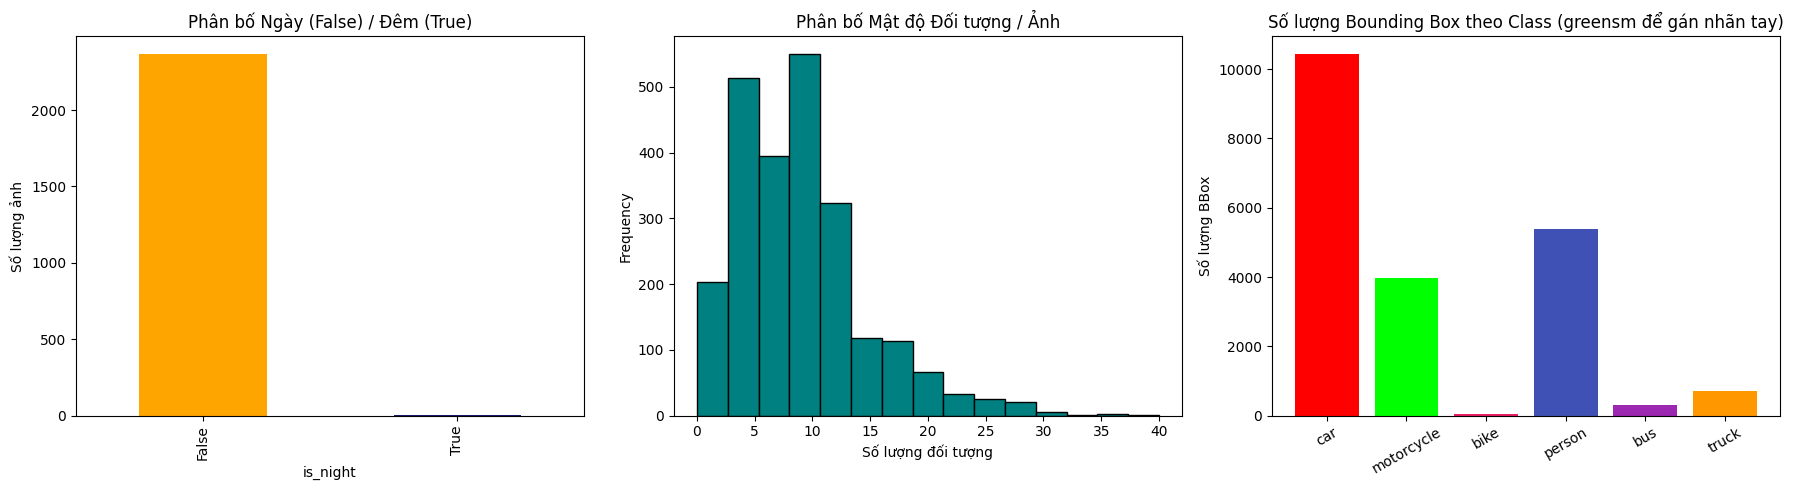

In [20]:
import json
import pandas as pd
import matplotlib.pyplot as plt

profile_file = DEFAULT_OUTPUT_DIR / "data_profile.json"
if profile_file.exists():
    with open(profile_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    rows = []
    class_totals = {c: 0 for c in GREENSM_CLASSES}

    for name, info in data.items():
        row = {
            "name": name,
            "vehicle_count": info.get("vehicle_count", 0),
            "brightness_v": info.get("brightness_v", 0.0),
            "laplacian_var": info.get("laplacian_var", 0.0),
            "is_night": info.get("tags", {}).get("is_night", False),
            "is_blur": info.get("tags", {}).get("is_blur", False),
            "has_small_object": info.get("tags", {}).get("has_small_object", False),
            "has_high_occlusion": info.get("tags", {}).get("has_high_occlusion", False),
            "is_dense_scene": info.get("tags", {}).get("is_dense_scene", False),
        }
        breakdown = info.get("class_breakdown", {})
        for c, count in breakdown.items():
            if c in class_totals:
                class_totals[c] += count
        rows.append(row)

    df = pd.DataFrame(rows)
    print(f"📊 Tổng quan tập dữ liệu: {len(df)} ảnh sống sót")
    print(df[["is_night", "is_blur", "vehicle_count", "has_high_occlusion", "has_small_object"]].describe())

    # Biểu đồ phân tích
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Biểu đồ 1: Ngày / Đêm
    df["is_night"].value_counts().plot(kind="bar", ax=axes[0], color=["#FFA500", "#191970"])
    axes[0].set_title("Phân bố Ngày (False) / Đêm (True)")
    axes[0].set_ylabel("Số lượng ảnh")

    # Biểu đồ 2: Mật độ đối tượng
    df["vehicle_count"].plot(kind="hist", bins=15, ax=axes[1], color="#008080", edgecolor="black")
    axes[1].set_title("Phân bố Mật độ Đối tượng / Ảnh")
    axes[1].set_xlabel("Số lượng đối tượng")

    # Biểu đồ 3: Phân bố các Class Pre-labeled
    prelabeled_classes = {k: v for k, v in class_totals.items() if k != "greensm"}
    colors = [CLASS_COLORS.get(c, "#333") for c in prelabeled_classes.keys()]
    axes[2].bar(prelabeled_classes.keys(), prelabeled_classes.values(), color=colors)
    axes[2].set_title("Số lượng Bounding Box theo Class (greensm để gán nhãn tay)")
    axes[2].set_ylabel("Số lượng BBox")
    plt.xticks(rotation=30)

    plt.tight_layout()
    plt.show()
else:
    print("⚠️ Chưa có file data_profile.json. Vui lòng chạy Bước 7 trước!")


## 📦 Bước 9: Đóng gói Chuẩn CVAT (Native XML 1.1 + Split Zip 50 frames)
Tự động tạo `annotations.xml` chuẩn CVAT 1.1 (đầy đủ 7 labels) và chia thành các file zip nhỏ (50 frame/zip).
- Import siêu tốc (< 1s cho file XML ~28KB)
- Sẵn sàng cho annotator gán nhãn `greensm` trên CVAT UI.

In [24]:
# ==============================================================================
# BƯỚC 9: ĐÓNG GÓI CHUẨN CVAT (Native XML 1.1 + Split Zip 1185 frames)
# ==============================================================================

"""
CVAT Packaging Module: Generates Native XML (CVAT 1.1) and Split YOLO ZIP archives
"""

import json
import zipfile
from pathlib import Path
from datetime import datetime
from PIL import Image

# Đã loại bỏ các lệnh import tương đối lỗi từ .config
# Sử dụng trực tiếp các biến toàn cục đã khai báo ở cell cấu hình phía trên:
# GREENSM_CLASSES, CLASS_COLORS, DEFAULT_BATCH_SIZE, DEFAULT_OUTPUT_DIR


def load_manifest(manifest_path):
    """Load manifest tracking file for previously packaged items."""
    manifest_path = Path(manifest_path)
    if manifest_path.exists():
        try:
            with open(manifest_path, "r", encoding="utf-8") as f:
                return json.load(f)
        except Exception:
            pass
    return {"zipped_files": [], "batches": []}


def save_manifest(manifest_path, manifest_data):
    """Save manifest tracking file."""
    manifest_path = Path(manifest_path)
    manifest_path.parent.mkdir(parents=True, exist_ok=True)
    with open(manifest_path, "w", encoding="utf-8") as f:
        json.dump(manifest_data, f, indent=2, ensure_ascii=False)


def create_cvat_xml_annotations(images_list, dedup_images_dir, pre_labels_dir, xml_path):
    """
    Generate native CVAT 1.1 / CVAT for images 1.1 XML annotation file.
    This format is natively supported by CVAT and avoids all path matching issues of YOLO.
    """
    dedup_images_dir = Path(dedup_images_dir)
    pre_labels_dir = Path(pre_labels_dir)
    xml_path = Path(xml_path)

    xml_lines = [
        '<?xml version="1.0" encoding="utf-8"?>',
        '<annotations>',
        '  <version>1.1</version>',
        '  <meta>',
        '    <task>',
        '      <id>1</id>',
        '      <name>GreenSM_PreLabels</name>',
        f'      <size>{len(images_list)}</size>',
        '      <mode>annotation</mode>',
        '      <labels>'
    ]

    for c in GREENSM_CLASSES:
        color = CLASS_COLORS.get(c, "#FFFFFF")
        xml_lines.append(f'        <label><name>{c}</name><color>{color}</color></label>')

    xml_lines.extend([
        '      </labels>',
        '    </task>',
        '  </meta>'
    ])

    total_boxes = 0

    for idx, img_file in enumerate(images_list):
        img_name = img_file.name
        img_path = dedup_images_dir / img_name

        try:
            with Image.open(img_path) as im:
                w, h = im.size
        except Exception:
            w, h = 1920, 1080

        xml_lines.append(f'  <image id="{idx}" name="{img_name}" width="{w}" height="{h}">')

        txt_name = f"{img_file.stem}.txt"
        txt_path = pre_labels_dir / txt_name

        if txt_path.exists():
            with open(txt_path, "r", encoding="utf-8") as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        try:
                            cls_id = int(parts[0])
                            xc, yc, bw, bh = map(float, parts[1:5])
                            label_name = GREENSM_CLASSES[cls_id] if cls_id < len(GREENSM_CLASSES) else "car"

                            xtl = max(0.0, (xc - bw / 2.0) * w)
                            ytl = max(0.0, (yc - bh / 2.0) * h)
                            xbr = min(float(w), (xc + bw / 2.0) * w)
                            ybr = min(float(h), (yc + bh / 2.0) * h)

                            xml_lines.append(
                                f'    <box label="{label_name}" occluded="0" xtl="{xtl:.2f}" ytl="{ytl:.2f}" '
                                f'xbr="{xbr:.2f}" ybr="{ybr:.2f}" z_order="0">\n    </box>'
                            )
                            total_boxes += 1
                        except Exception:
                            continue

        xml_lines.append('  </image>')

    xml_lines.append('</annotations>')

    with open(xml_path, "w", encoding="utf-8") as f:
        f.write("\n".join(xml_lines))

    return total_boxes


def create_single_zip_batch(zip_path, images_chunk, pre_labels_dir, include_images=True):
    """Helper to create a single YOLO 1.1 zip file with exact filename matching."""
    zip_path = Path(zip_path)
    pre_labels_dir = Path(pre_labels_dir)

    obj_names_content = "\n".join(GREENSM_CLASSES) + "\n"
    obj_data_content = (
        f"classes = {len(GREENSM_CLASSES)}\n"
        f"train = train.txt\n"
        f"names = obj.names\n"
        f"backup = backup/\n"
    )

    train_txt_lines = []

    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        zf.writestr("obj.names", obj_names_content)
        zf.writestr("obj.data", obj_data_content)

        for img_file in images_chunk:
            stem = img_file.stem
            img_name = img_file.name
            txt_name = f"{stem}.txt"

            train_txt_lines.append(f"{img_name}\n")
            train_txt_lines.append(f"obj_train_data/{img_name}\n")

            if include_images and img_file.exists():
                zf.write(img_file, arcname=f"obj_train_data/{img_name}")
                zf.write(img_file, arcname=img_name)

            txt_file = pre_labels_dir / txt_name
            if txt_file.exists():
                txt_data = txt_file.read_bytes()
            else:
                txt_data = b""

            zf.writestr(f"obj_train_data/{txt_name}", txt_data)
            zf.writestr(txt_name, txt_data)

        zf.writestr("train.txt", "".join(train_txt_lines))


def create_cvat_zip_package(output_dir=DEFAULT_OUTPUT_DIR, zip_dir=None, batch_size=DEFAULT_BATCH_SIZE, force_all=False):
    """
    Creates CVAT Native XML packages and split YOLO batches.
    """
    output_dir = Path(output_dir).resolve()
    zip_dir = Path(zip_dir).resolve() if zip_dir else output_dir / "cvat_uploads"

    dedup_images_dir = output_dir / "deduplicated_images"
    pre_labels_dir = output_dir / "pre_labels"
    manifest_path = output_dir / ".zipped_manifest.json"

    if not dedup_images_dir.exists():
        print(f"[ERROR] Deduplicated images directory does not exist: {dedup_images_dir}")
        return None

    manifest = load_manifest(manifest_path)
    already_zipped = set(manifest.get("zipped_files", [])) if not force_all else set()

    image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tiff', '.tif'}
    all_images = sorted([
        f for f in dedup_images_dir.iterdir()
        if f.is_file() and f.suffix.lower() in image_extensions
    ])

    if not all_images:
        print(f"[INFO] No images found in {dedup_images_dir}.")
        return None

    new_images = [img for img in all_images if img.name not in already_zipped]

    if not new_images:
        print(f"[INFO] All {len(all_images)} image(s) in '{dedup_images_dir.name}' have ALREADY been packaged in previous ZIP batch(es).")
        print(f"       No new un-zipped images found. Skipping packaging to prevent duplication.")
        return None

    print(f"[INFO] Found {len(new_images)} NEW un-packaged image(s) out of {len(all_images)} total.")
    zip_dir.mkdir(parents=True, exist_ok=True)
    timestamp_str = datetime.now().strftime("%Y%m%d_%H%M%S")

    # 1. Master CVAT Native XML (ALL Images)
    master_xml_filename = f"cvat_annotations_ALL_{timestamp_str}.xml"
    master_xml_path = zip_dir / master_xml_filename
    master_xml_zip_filename = f"cvat_NATIVE_XML_ALL_{timestamp_str}.zip"
    master_xml_zip_path = zip_dir / master_xml_zip_filename

    total_boxes = create_cvat_xml_annotations(new_images, dedup_images_dir, pre_labels_dir, master_xml_path)
    with zipfile.ZipFile(master_xml_zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        zf.write(master_xml_path, arcname="annotations.xml")

    # 2. Split Batches (50 images/part)
    chunks = [new_images[i:i + batch_size] for i in range(0, len(new_images), batch_size)]
    total_chunks = len(chunks)
    packaged_names = []

    print(f"\n=== GENERATING {total_chunks} SPLIT BATCHES ({batch_size} IMAGES/PART) ===")
    for idx, chunk in enumerate(chunks, start=1):
        # Image + YOLO zip
        zip_filename = f"cvat_batch_{timestamp_str}_part{idx:02d}_of_{total_chunks:02d}.zip"
        zip_path = zip_dir / zip_filename
        create_single_zip_batch(zip_path, chunk, pre_labels_dir, include_images=True)

        # Native XML zip for this part
        part_xml_filename = f"cvat_NATIVE_XML_part{idx:02d}_of_{total_chunks:02d}.xml"
        part_xml_path = zip_dir / part_xml_filename
        part_xml_zip_path = zip_dir / f"cvat_NATIVE_XML_part{idx:02d}_of_{total_chunks:02d}.zip"

        create_cvat_xml_annotations(chunk, dedup_images_dir, pre_labels_dir, part_xml_path)
        with zipfile.ZipFile(part_xml_zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
            zf.write(part_xml_path, arcname="annotations.xml")

        print(f"[INFO] Part [{idx}/{total_chunks}] ({len(chunk)} images):")
        print(f"       - Image ZIP: {zip_filename}")
        print(f"       - Native XML ZIP: {part_xml_zip_path.name}")

        for img in chunk:
            packaged_names.append(img.name)

    manifest["zipped_files"].extend(packaged_names)
    manifest["batches"].append({
        "timestamp": datetime.now().isoformat(),
        "image_count": len(packaged_names),
        "total_boxes": total_boxes,
        "master_xml": master_xml_zip_filename
    })
    save_manifest(manifest_path, manifest)

    print(f"\n[SUCCESS] Packaging Completed!")
    print(f"  ⭐ Dùng file XML này nếu Task chứa TOÀN BỘ {len(new_images)} ảnh: {master_xml_zip_path.name}")
    print(f"  ⭐ Dùng file XML part tương ứng nếu bạn tạo Task theo từng Part:")
    for idx in range(1, total_chunks + 1):
        print(f"     - Task Part {idx}: cvat_NATIVE_XML_part{idx:02d}_of_{total_chunks:02d}.zip")

    return master_xml_zip_path


print("📦 Bắt đầu đóng gói cho CVAT...")
zip_dir = DEFAULT_OUTPUT_DIR / 'cvat_uploads'
create_cvat_zip_package(
    output_dir=DEFAULT_OUTPUT_DIR,
    zip_dir=zip_dir,
    batch_size=DEFAULT_BATCH_SIZE,
    force_all=True
)

📦 Bắt đầu đóng gói cho CVAT...
[INFO] Found 2369 NEW un-packaged image(s) out of 2369 total.

=== GENERATING 2 SPLIT BATCHES (1185 IMAGES/PART) ===
[INFO] Part [1/2] (1185 images):
       - Image ZIP: cvat_batch_20261012_022506_part01_of_02.zip
       - Native XML ZIP: cvat_NATIVE_XML_part01_of_02.zip
[INFO] Part [2/2] (1184 images):
       - Image ZIP: cvat_batch_20261012_022506_part02_of_02.zip
       - Native XML ZIP: cvat_NATIVE_XML_part02_of_02.zip

[SUCCESS] Packaging Completed!
  ⭐ Dùng file XML này nếu Task chứa TOÀN BỘ 2369 ảnh: cvat_NATIVE_XML_ALL_20261012_022506.zip
  ⭐ Dùng file XML part tương ứng nếu bạn tạo Task theo từng Part:
     - Task Part 1: cvat_NATIVE_XML_part01_of_02.zip
     - Task Part 2: cvat_NATIVE_XML_part02_of_02.zip


PosixPath('/content/data/outputs/cvat_uploads/cvat_NATIVE_XML_ALL_20261012_022506.zip')

## 💾 Bước 10: Tải Kết quả về Máy tính (Download to Local)
Tải các file zip CVAT và báo cáo profiling trực tiếp về máy tính của bạn.

In [25]:
from google.colab import files
from glob import glob

zip_dir = DEFAULT_OUTPUT_DIR / "cvat_uploads"
zip_files = glob(os.path.join(str(zip_dir), "*.zip"))
print(f"📦 Tìm thấy {len(zip_files)} file zip CVAT sẵn sàng tải về:")
for zf in zip_files:
    print(f" - {zf}")
    # Bỏ comment dòng dưới nếu muốn tự động tải về trình duyệt:
    # files.download(zf)

# Tải file báo cáo JSON
report_path = DEFAULT_OUTPUT_DIR / "data_profile.json"
if report_path.exists():
    print(f"📄 Tải file báo cáo profiling: {report_path}")
    # files.download(str(report_path))


📦 Tìm thấy 5 file zip CVAT sẵn sàng tải về:
 - data/outputs/cvat_uploads/cvat_NATIVE_XML_part01_of_02.zip
 - data/outputs/cvat_uploads/cvat_batch_20261012_022506_part02_of_02.zip
 - data/outputs/cvat_uploads/cvat_batch_20261012_022506_part01_of_02.zip
 - data/outputs/cvat_uploads/cvat_NATIVE_XML_part02_of_02.zip
 - data/outputs/cvat_uploads/cvat_NATIVE_XML_ALL_20261012_022506.zip
📄 Tải file báo cáo profiling: data/outputs/data_profile.json
